# Etapa 6. Experimentos: Bloom Filter frente a set y Count-Min Sketch frente a dict

**Proyecto EDA 2026-2, Grupo 1, escenario B.** Responsable de la etapa 6: Aris.

El enunciado pide comparar las estructuras probabilísticas con una alternativa exacta en **tiempo, memoria, falsos positivos y error de frecuencia**, con tamaños de 1K a 10M y gráficos log-log.

Las mediciones las hace `scripts/etapa6_experimentos.py` en segundo plano y quedan en `results/etapa6_*.csv`. Este notebook solo lee esos archivos y grafica, así que se ejecuta en segundos.

| Experimento | Estructura | Alternativa exacta | Datos |
| --- | --- | --- | --- |
| Pertenencia | `BloomFilter` con p = 0.01 | `set` de Python | n claves distintas con forma de tarjeta; 100 000 claves ausentes para medir falsos positivos |
| Frecuencia | `CountMinSketch` con ε = 0.001, δ = 0.01 | `dict` de Python | n eventos sobre n/10 claves con frecuencias Zipf (a = 1.2) |
| Compromiso memoria-error | CMS con ε de 0.1 a 0.0001 | `Counter` | 1M eventos Zipf |

**Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 3 para 10M. A 10M, una construcción del Bloom Filter en Python puro tarda cerca de 30 s; 100 repeticiones serían casi una hora por estructura. La desviación estándar a 1M ya es menor al 3 % del promedio. La memoria se mide en una pasada aparte con `tracemalloc`, sin medir tiempo, porque el rastreo de memoria hace más lenta cada asignación.

In [1]:
import json
import platform
import sys
import time
from collections import Counter
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config

R = config.CARPETA_RESULTADOS
plataforma = json.loads((R / "etapa6_plataforma.json").read_text(encoding="utf-8"))
bloom = pd.read_csv(R / "etapa6_bloom.csv")
cms = pd.read_csv(R / "etapa6_cms.csv")
epsilon = pd.read_csv(R / "etapa6_cms_epsilon.csv")
plataforma

{'sistema': 'macOS-26.6.2-arm64-arm-64bit',
 'procesador': 'arm',
 'nucleos': 10,
 'ram_gb': 17.2,
 'python': '3.12.13',
 'semilla': 42,
 'p_fp': 0.01,
 'epsilon': 0.001,
 'delta': 0.01,
 'zipf_a': 1.2,
 'repeticiones': {'1000': 100,
  '10000': 100,
  '100000': 20,
  '1000000': 5,
  '10000000': 3}}

## 1. Bloom Filter frente a set

### Tiempo por operación

Insertar y consultar cuestan O(k) en el Bloom Filter y O(1) esperado en el `set`, así que el tiempo **por operación** debería ser constante en n para los dos (pendiente 0 en log-log). El `set` está implementado en C dentro del intérprete; el Bloom Filter está escrito en Python, por eso es más lento en valor absoluto aunque la complejidad sea la misma.

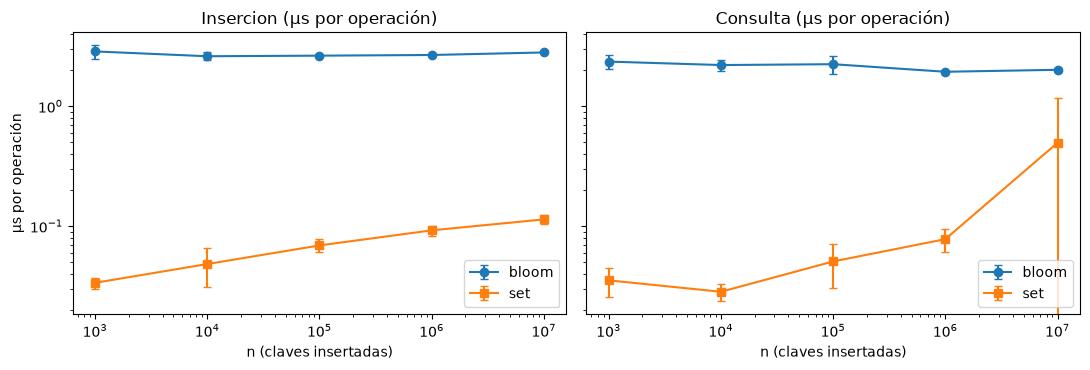

,n,repeticiones,k,insercion_bloom_us,insercion_bloom_std_us,insercion_set_us,consulta_bloom_us,consulta_set_us
0,1000,100,7,2.852,0.366,0.034,2.347,0.035
1,10000,100,7,2.601,0.194,0.048,2.196,0.028
2,100000,20,7,2.630,0.091,0.069,2.232,0.051
3,1000000,5,7,2.664,0.021,0.092,1.931,0.078
4,10000000,3,7,2.797,0.013,0.114,2.005,0.494


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, op in zip(axes, ["insercion", "consulta"]):
    for estructura, marca in [("bloom", "o"), ("set", "s")]:
        ax.errorbar(bloom["n"], bloom[f"{op}_{estructura}_us"], yerr=bloom[f"{op}_{estructura}_std_us"],
                    marker=marca, capsize=3, label=estructura)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n (claves insertadas)"); ax.set_title(f"{op.capitalize()} (µs por operación)")
    ax.legend()
axes[0].set_ylabel("µs por operación")
fig.tight_layout(); fig.savefig(R / "etapa6_bloom_tiempo.png", dpi=150); plt.show()
bloom[["n", "repeticiones", "k", "insercion_bloom_us", "insercion_bloom_std_us", "insercion_set_us",
       "consulta_bloom_us", "consulta_set_us"]].round(3)

### Memoria

El Bloom Filter ocupa m = −n·ln p / (ln 2)² bits, es decir, **9.6 bits por clave** con p = 0.01, sin importar el largo de la clave. El `set` guarda una referencia y un hash por posición (más el espacio libre de la tabla) y además necesita **las claves mismas**, porque en un servicio real la lista de señalados llega del stream y el `set` debe conservar cada texto. Las dos crecen como O(n), con pendiente 1 en log-log, y la diferencia está en la constante.

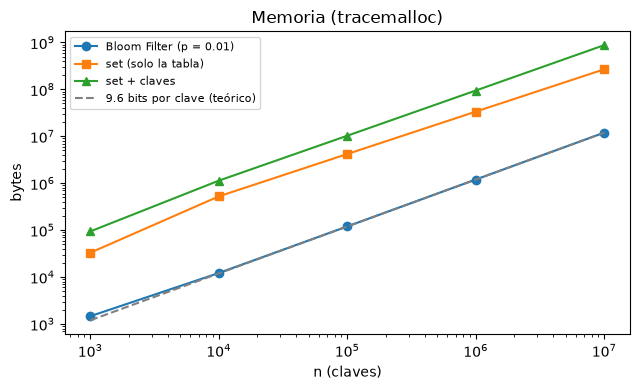

,n,memoria_bloom_bytes,memoria_set_bytes,set_mas_claves_bytes,bytes_por_clave_bloom,bytes_por_clave_set+claves,veces_menos_memoria
0,1000,1464,32984,93984,1.46,93.98,64.20
1,10000,12199,524504,1134504,1.22,113.45,93.00
2,100000,120031,4194520,10294520,1.20,102.95,85.77
3,1000000,1198350,33554648,94554648,1.20,94.55,78.90
4,10000000,11981540,268435672,878435672,1.20,87.84,73.32


In [3]:
bloom["set_mas_claves_bytes"] = bloom["memoria_set_bytes"] + bloom["memoria_claves_bytes"]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(bloom["n"], bloom["memoria_bloom_bytes"], marker="o", label="Bloom Filter (p = 0.01)")
ax.plot(bloom["n"], bloom["memoria_set_bytes"], marker="s", label="set (solo la tabla)")
ax.plot(bloom["n"], bloom["set_mas_claves_bytes"], marker="^", label="set + claves")
ax.plot(bloom["n"], bloom["n"] * 9.585 / 8, ls="--", color="gray", label="9.6 bits por clave (teórico)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (claves)"); ax.set_ylabel("bytes")
ax.set_title("Memoria (tracemalloc)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(R / "etapa6_bloom_memoria.png", dpi=150); plt.show()

tabla = bloom[["n", "memoria_bloom_bytes", "memoria_set_bytes", "set_mas_claves_bytes"]].copy()
tabla["bytes_por_clave_bloom"] = tabla["memoria_bloom_bytes"] / tabla["n"]
tabla["bytes_por_clave_set+claves"] = tabla["set_mas_claves_bytes"] / tabla["n"]
tabla["veces_menos_memoria"] = tabla["set_mas_claves_bytes"] / tabla["memoria_bloom_bytes"]
tabla.round(2)

### Falsos positivos y falsos negativos

Se consultan 100 000 claves que nunca se insertaron. Todas las que dan positivo son falsos positivos. Además se comprueba que ninguna clave insertada da negativo.

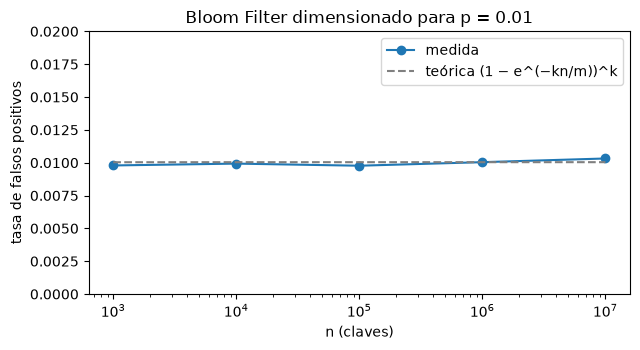

Falsos negativos en todos los tamaños: [0, 0, 0, 0, 0]


,n,m_bits,k,tasa_fp_medida,tasa_fp_teorica
0,1000,9586,7,0.00979,0.010035
1,10000,95851,7,0.00993,0.010039
2,100000,958506,7,0.00977,0.010039
3,1000000,9585059,7,0.01004,0.010039
4,10000000,95850584,7,0.01032,0.010039


In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(bloom["n"], bloom["tasa_fp_medida"], marker="o", label="medida")
ax.plot(bloom["n"], bloom["tasa_fp_teorica"], ls="--", color="gray", label="teórica (1 − e^(−kn/m))^k")
ax.set_xscale("log"); ax.set_ylim(0, 0.02); ax.set_xlabel("n (claves)"); ax.set_ylabel("tasa de falsos positivos")
ax.set_title("Bloom Filter dimensionado para p = 0.01"); ax.legend()
fig.tight_layout(); fig.savefig(R / "etapa6_bloom_fp.png", dpi=150); plt.show()
print("Falsos negativos en todos los tamaños:", bloom["falsos_negativos"].tolist())
bloom[["n", "m_bits", "k", "tasa_fp_medida", "tasa_fp_teorica"]]

## 2. Count-Min Sketch frente a dict

### Tiempo y memoria

Actualizar y estimar cuestan O(d) en el CMS y O(1) esperado en el `dict`. La memoria del CMS es fija, w·d contadores (w = 2 719 y d = 5, unos 109 KB), mientras que el `dict` crece con el número de claves distintas.

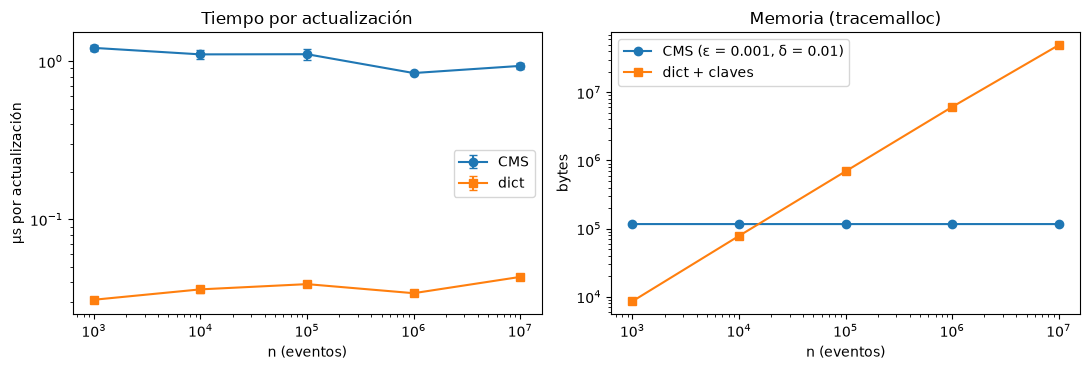

,n,repeticiones,claves_distintas,actualizacion_cms_us,actualizacion_dict_us,consulta_cms_us,consulta_dict_us,memoria_cms_bytes,dict_mas_claves_bytes
0,1000,100,98,1.215,0.031,1.268,0.027,116288,8556
1,10000,100,959,1.105,0.036,1.178,0.025,116264,77914
2,100000,20,8950,1.108,0.039,1.271,0.030,116264,691940
3,1000000,5,77262,0.842,0.034,0.949,0.033,116264,6102180
4,10000000,3,627550,0.934,0.043,1.538,0.038,116264,49318068


In [5]:
cms["dict_mas_claves_bytes"] = cms["memoria_dict_bytes"] + cms["memoria_claves_bytes"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.errorbar(cms["n"], cms["actualizacion_cms_us"], yerr=cms["actualizacion_cms_std_us"], marker="o", capsize=3, label="CMS")
ax.errorbar(cms["n"], cms["actualizacion_dict_us"], yerr=cms["actualizacion_dict_std_us"], marker="s", capsize=3, label="dict")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (eventos)"); ax.set_ylabel("µs por actualización")
ax.set_title("Tiempo por actualización"); ax.legend()
ax = axes[1]
ax.plot(cms["n"], cms["memoria_cms_bytes"], marker="o", label="CMS (ε = 0.001, δ = 0.01)")
ax.plot(cms["n"], cms["dict_mas_claves_bytes"], marker="s", label="dict + claves")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (eventos)"); ax.set_ylabel("bytes")
ax.set_title("Memoria (tracemalloc)"); ax.legend()
fig.tight_layout(); fig.savefig(R / "etapa6_cms_tiempo_memoria.png", dpi=150); plt.show()
cms[["n", "repeticiones", "claves_distintas", "actualizacion_cms_us", "actualizacion_dict_us", "consulta_cms_us",
     "consulta_dict_us", "memoria_cms_bytes", "dict_mas_claves_bytes"]].round(3)

### Error de frecuencia

Para cada clave distinta se compara la estimación del CMS con la frecuencia exacta del `dict`. La garantía es error ≤ ε·N con probabilidad 1 − δ, de modo que a lo más un 1 % de las claves puede superar la cota. Como N crece con el stream y la memoria es fija, el error absoluto crece con n.

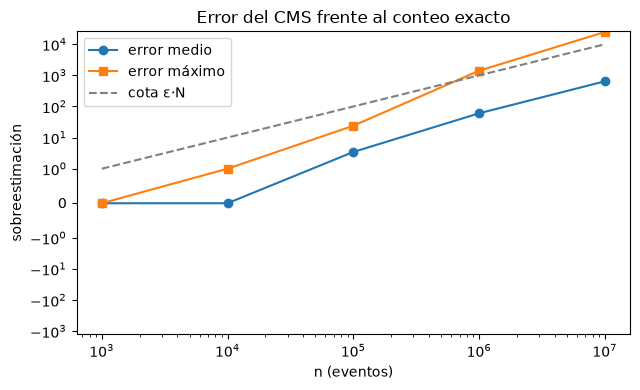

,n,claves_distintas,error_medio,error_max,cota_eps_n,fraccion_sobre_cota,subestimaciones,error_relativo_top10
0,1000,98,0.000000,0,0.999736,0.000000,0,0.000000
1,10000,959,0.001043,1,9.997359,0.000000,0,0.000000
2,100000,8950,3.443575,24,99.973587,0.000000,0,0.001422
3,1000000,77262,60.356152,1411,999.735869,0.000013,0,0.002458
4,10000000,627550,643.741297,24793,9997.358692,0.000008,0,0.002738


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(cms["n"], cms["error_medio"], marker="o", label="error medio")
ax.plot(cms["n"], cms["error_max"], marker="s", label="error máximo")
ax.plot(cms["n"], cms["cota_eps_n"], ls="--", color="gray", label="cota ε·N")
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1); ax.set_xlabel("n (eventos)"); ax.set_ylabel("sobreestimación")
ax.set_title("Error del CMS frente al conteo exacto"); ax.legend()
fig.tight_layout(); fig.savefig(R / "etapa6_cms_error.png", dpi=150); plt.show()
cms[["n", "claves_distintas", "error_medio", "error_max", "cota_eps_n", "fraccion_sobre_cota", "subestimaciones",
     "error_relativo_top10"]]

### Compromiso memoria-error

El mismo stream de 1M eventos con distintos ε. La memoria crece como 1/ε y el error cae en la misma proporción, así que ε es el parámetro con el que se dimensiona el CMS. En la etapa 6 cada ventana tiene unas decenas de órdenes, por lo que basta ε = 0.01.

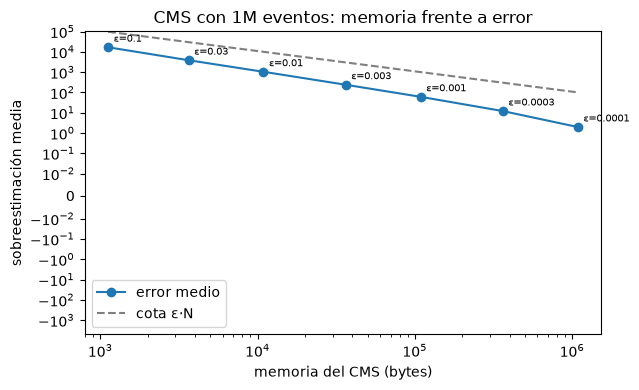

,n,epsilon,w,d,memoria_cms_bytes,error_medio,error_max,subestimaciones,cota_eps_n,fraccion_sobre_cota,error_relativo_top10
0,1000000,0.1000,28,5,1120,16741.599308,194347,0,97081.493874,0.002435,0.814934
1,1000000,0.0300,91,5,3640,3840.640425,181982,0,29871.228884,0.000544,0.161274
2,1000000,0.0100,272,5,10880,1036.447066,179635,0,9993.683193,0.000350,0.043123
3,1000000,0.0030,907,5,36280,238.162136,7854,0,2997.003118,0.000013,0.011229
4,1000000,0.0010,2719,5,108760,60.503723,1467,0,999.735869,0.000013,0.002779
5,1000000,0.0003,9061,5,362440,11.994949,113,0,299.997995,0.000000,0.000467
6,1000000,0.0001,27183,5,1087320,1.961965,23,0,99.999332,0.000000,0.000055


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(epsilon["memoria_cms_bytes"], epsilon["error_medio"], marker="o", label="error medio")
ax.plot(epsilon["memoria_cms_bytes"], epsilon["cota_eps_n"], ls="--", color="gray", label="cota ε·N")
for _, f in epsilon.iterrows():
    ax.annotate(f"ε={f['epsilon']:g}", (f["memoria_cms_bytes"], max(f["error_medio"], 1e-3)), fontsize=7,
                textcoords="offset points", xytext=(4, 4))
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=0.01); ax.set_xlabel("memoria del CMS (bytes)")
ax.set_ylabel("sobreestimación media"); ax.set_title("CMS con 1M eventos: memoria frente a error"); ax.legend()
fig.tight_layout(); fig.savefig(R / "etapa6_cms_epsilon.png", dpi=150); plt.show()
epsilon